In [70]:
from posydon.popsyn.synthetic_population import Population
import pandas as pd
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm

# Import Sana+12 period distribution
from posydon.popsyn.distributions import Sana12Period
from scipy.stats import gaussian_kde

from helper_functions import calc_Teff, classify_WR_type

metallicity = 1.0

data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']

WR_types = []
time_array = []
weight_array = []
state_array = []
key_array = []
star_array = []  # Track whether entry is from S1 or S2
period_array = []
separation_array = []
Teff_array = []
L_array = []
optical_depth_array = []
surface_H_array = []
surface_He_array = []
mass_array = []
mass_companion_array = []
radius_array = []
Mdot_array = []
companion_array = []
S1_state_array = []
surface_C = []
optical_depth = []

for key in tqdm(S1_WR_data):
    data = S1_WR_data[key]['data']
    weights = S1_WR_data[key]['weights']
    optical_depth_array.extend(S1_WR_data[key]['optical_depth'])
    
    surface_H_array.extend(data['S1_surface_h1'].values)
    surface_He_array.extend(data['S1_surface_he4'].values)
    Teff = 10**calc_Teff(data['S1_log_L'], data['S1_log_R'])
        
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    S1_state_array.extend(data['S1_state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S1'] * len(data))  # Mark as S1
    Teff_array.extend(Teff)
    L_array.extend(10**data['S1_log_L'].values)
    mass_array.extend(data['S1_mass'].values)
    mass_companion_array.extend(data['S2_mass'].values)
    radius_array.extend(10**data['S1_log_R'].values)
    Mdot_array.extend(10**data['S1_lg_mdot'].values)
    companion_array.extend(data['S2_state'].values)
    
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S1_mass'].values,
                                        data['S2_mass'].values)
    
    separation_array.extend(sep)
    
    
for key in tqdm(S2_WR_data):
    data = S2_WR_data[key]['data']
    weights = S2_WR_data[key]['weights']
    optical_depth_array.extend(S2_WR_data[key]['optical_depth'])
    
    surface_H_array.extend(data['S2_surface_h1'].values)
    surface_He_array.extend(data['S2_surface_he4'].values)
    Teff = 10**calc_Teff(data['S2_log_L'], data['S2_log_R'])
    
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S2'] * len(data))  # Mark as S2
    Teff_array.extend(Teff)
    L_array.extend(10**data['S2_log_L'].values)
    mass_array.extend(data['S2_mass'].values)
    mass_companion_array.extend(data['S1_mass'].values)
    radius_array.extend(10**data['S2_log_R'].values)
    Mdot_array.extend(10**data['S2_lg_mdot'].values)
    companion_array.extend(data['S1_state'])
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S2_mass'].values,
                                        data['S1_mass'].values)
    S1_state_array.extend(data['S2_state'].values)
    separation_array.extend(sep)
    

WR_types = np.array(WR_types)
time_array = np.array(time_array)
weight_array = np.array(weight_array)
state_array = np.array(state_array)
key_array = np.array(key_array)
star_array = np.array(star_array)  # Convert to array
period_array = np.array(period_array)
separation_array = np.array(separation_array)
Teff_array = np.array(Teff_array)
L_array = np.array(L_array)
optical_depth_array = np.array(optical_depth_array)
surface_H_array = np.array(surface_H_array)
surface_He_array = np.array(surface_He_array)
mass_array = np.array(mass_array)
radius_array = np.array(radius_array)
Mdot_array = np.array(Mdot_array)
companion_array = np.array(companion_array)
mass_companion_array = np.array(mass_companion_array)

100%|██████████| 38190/38190 [00:23<00:00, 1658.02it/s]


In [71]:
cmap_m = plt.get_cmap("coolwarm", 8)
tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

WNL =  (surface_H_array > 0.05) & (surface_H_array <= 0.4) & (optical_depth_array > 1.5) & ~(np.char.find(S1_state_array, 'H_burning') != -1)
WNE = (surface_H_array <= 0.05) & (surface_He_array >= 0.7) & (optical_depth_array > 1.5)
WC = (surface_H_array <= 0.001) & (surface_He_array < 0.7) & (optical_depth_array > 1.5)
WR_mask =( WNL | WNE | WC )

binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
single_star_mask = (state_array == 'disrupted') | (state_array == 'merged')
WR_binary_fraction = np.sum(weight_array[binary_mask & (WR_mask)]) / np.sum(weight_array[(binary_mask | single_star_mask) & (WR_mask)])
print('metallicity:', metallicity)
print(f"Binary fraction among WR stars: {WR_binary_fraction:.2f}")
print('binary WC: ', np.sum(weight_array[binary_mask & WC]) / np.sum(weight_array[(binary_mask | single_star_mask) & WC]))
print('binary WNE: ', np.sum(weight_array[binary_mask & WNE]) / np.sum(weight_array[(binary_mask | single_star_mask) & WNE]))
print('binary WNL: ', np.sum(weight_array[binary_mask & WNL]) / np.sum(weight_array[(binary_mask | single_star_mask) & WNL]))
print('WC/WNE ratio: ', np.sum(weight_array[WC]) / np.sum(weight_array[WNE]))
print('WC/(WNE+WNL) ratio: ', np.sum(weight_array[WC]) / (np.sum(weight_array[WNE | WNL])))
print('WC/WR ratio: ', np.sum(weight_array[WC]) / np.sum(weight_array[WR_mask]))
print('WNE/WR ratio: ', np.sum(weight_array[WNE]) / np.sum(weight_array[WR_mask]))
print('WNL/WR ratio: ', np.sum(weight_array[WNL]) / np.sum(weight_array[WR_mask]))

metallicity: 1.0
Binary fraction among WR stars: 0.71
binary WC:  0.6973039669597129
binary WNE:  0.8420167870508042
binary WNL:  0.4280732196444364
WC/WNE ratio:  0.5854458356950426
WC/(WNE+WNL) ratio:  0.40861656513166006
WC/WR ratio:  0.2900836006379545
WNE/WR ratio:  0.4954917824183797
WNL/WR ratio:  0.21442461694366524


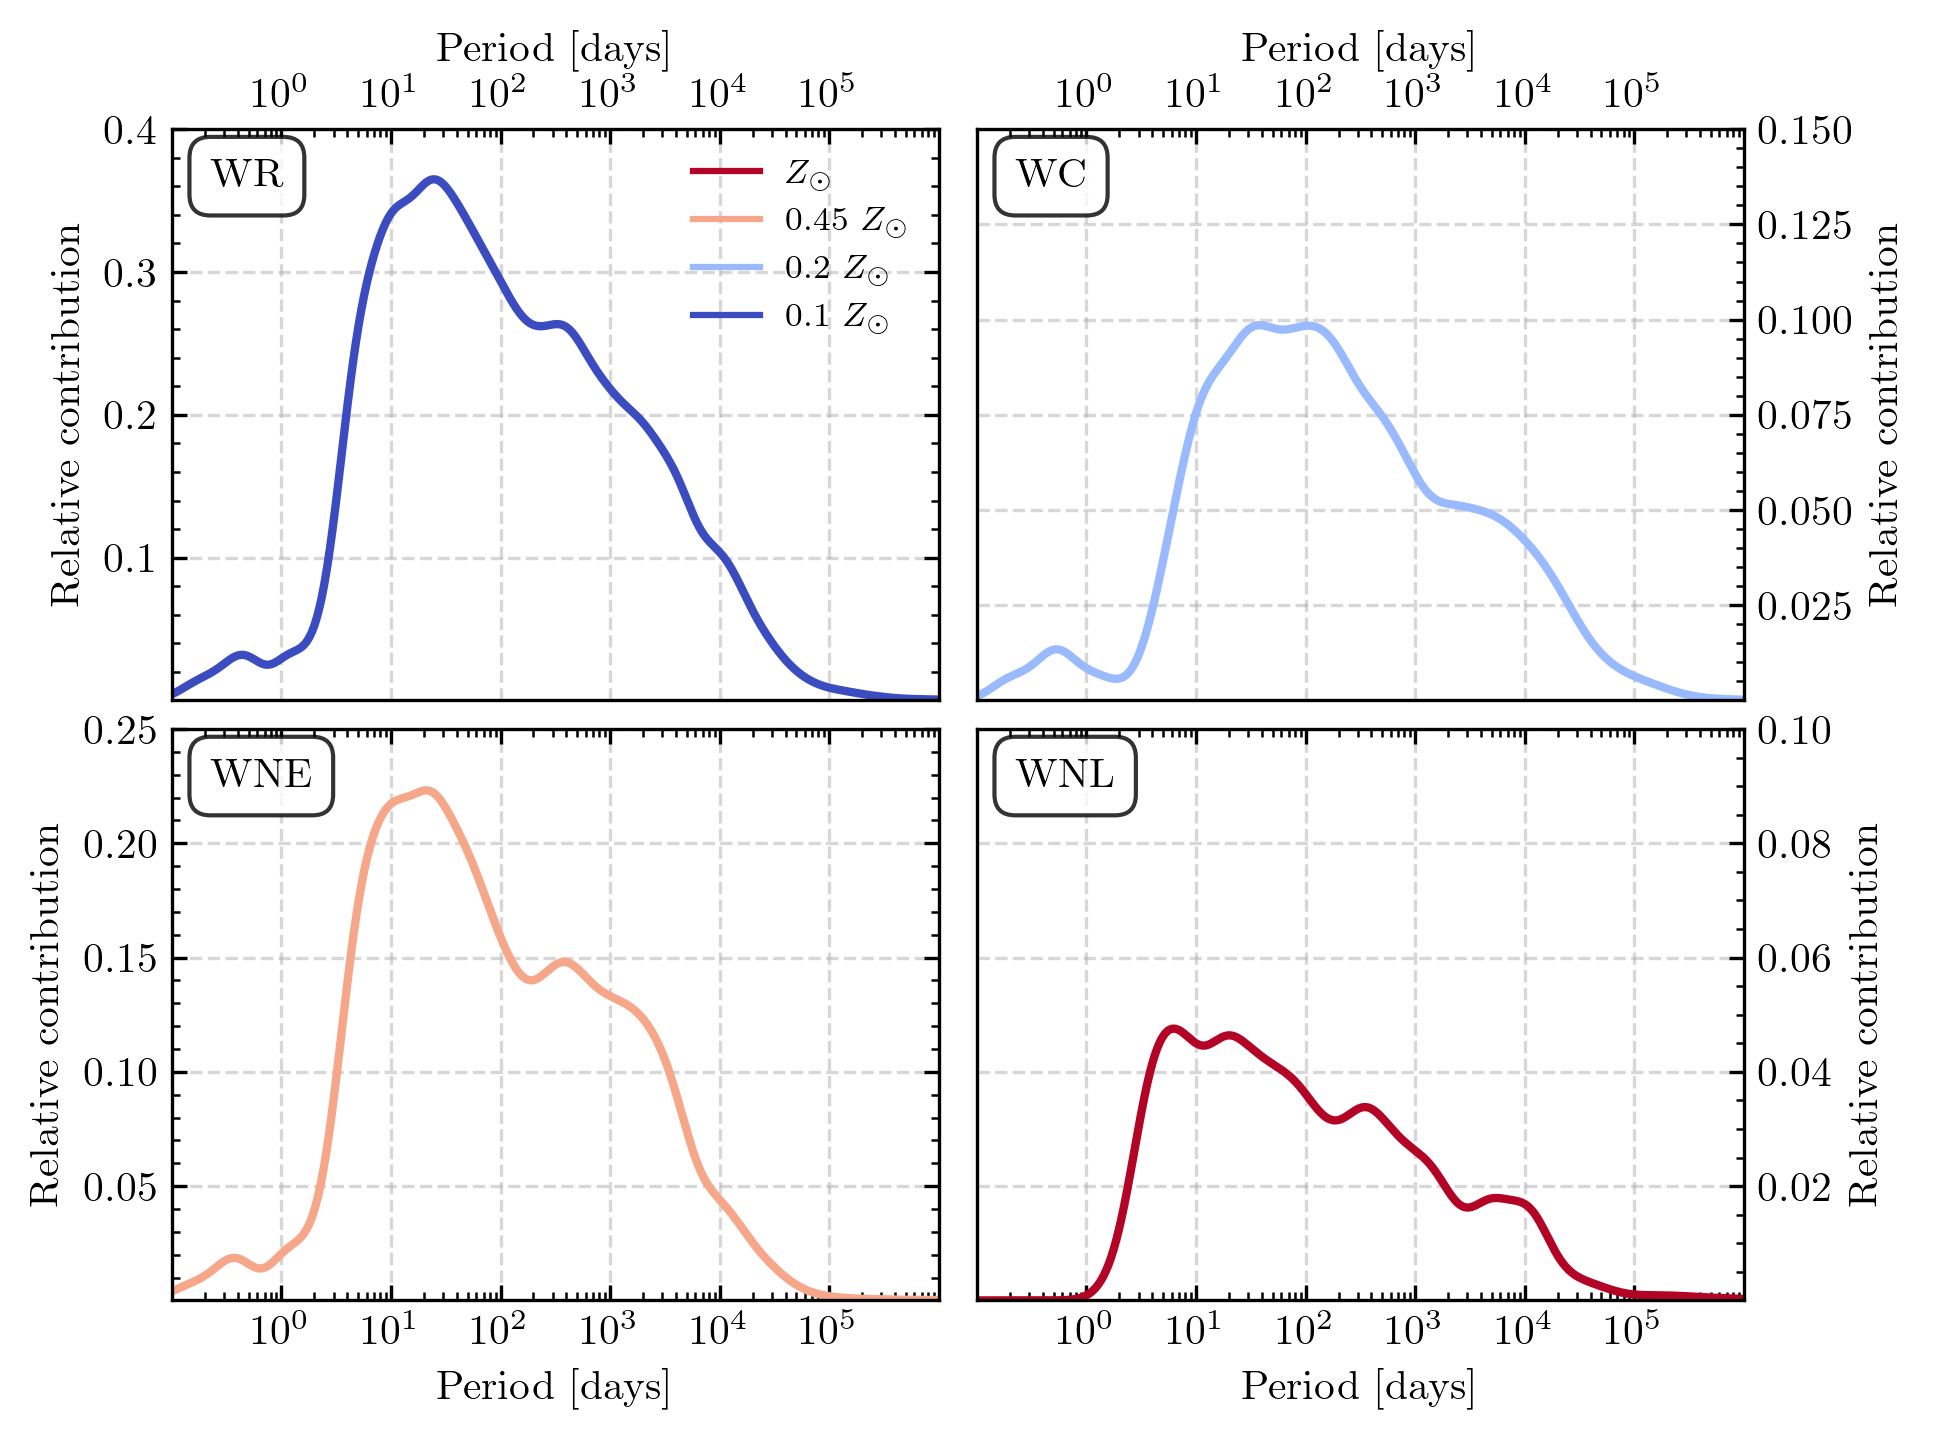

In [73]:

fig, axes = plt.subplots(2, 2, figsize=(3.38*2, 2.535*2))
plt.subplots_adjust(hspace=0.05, wspace=0.05)

x_eval = np.linspace(-1,7, 1000)

total_solar = np.sum(weight_array[(binary_mask) & (WNL | WNE | WC)])

# plot WR total
period_selection = period_array[(binary_mask) & (WNL | WNE | WC)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL | WNE | WC)])
kde_eval = kde(x_eval)
axes[0,0].plot(10**x_eval, kde_eval, color=cmap_m(0), label='', linewidth=2)

axes[0,0].text(0.05, 0.95, 'WR', transform=axes[0,0].transAxes, verticalalignment='top', horizontalalignment='left', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black', alpha=0.8))

# plot WC 
period_selection = period_array[(binary_mask) & WC]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & WC])
kde_eval = kde(x_eval)

weight = np.sum(weight_array[(binary_mask) & WC]) / total_solar
axes[0,1].plot(10**x_eval, kde_eval * weight, color=cmap_m(2), label='', linewidth=2)
axes[0,1].text(0.05, 0.95, 'WC', transform=axes[0,1].transAxes, verticalalignment='top', horizontalalignment='left', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black', alpha=0.8))


# plot WNE
period_selection = period_array[(binary_mask) & WNE]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & WNE])
kde_eval = kde(x_eval)
weight = np.sum(weight_array[(binary_mask) & WNE]) / total_solar
axes[1,0].plot(10**x_eval, kde_eval * weight, color=cmap_m(5), label='', linewidth=2)
axes[1,0].text(0.05, 0.95, 'WNE', transform=axes[1,0].transAxes, verticalalignment='top', horizontalalignment='left', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black', alpha=0.8))

# PLot WNL
period_selection = period_array[(binary_mask) & WNL]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & WNL])
kde_eval = kde(x_eval)

weight = np.sum(weight_array[(binary_mask) & WNL]) / total_solar
axes[1,1].plot(10**x_eval, kde_eval * weight, color=cmap_m(7), label='', linewidth=2)
axes[1,1].text(0.05, 0.95, 'WNL', transform=axes[1,1].transAxes, verticalalignment='top', horizontalalignment='left', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black', alpha=0.8))

for ax in axes.flatten():
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xlabel('Period [days]')
    ax.set_ylabel('Relative contribution')
    ax.set_xticks([1, 10, 100, 1000, 10000, 100000])
    ax.grid(True, which='major', ls='--', alpha=0.5)
    
for ax in axes[0]:
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    ax.set_xticks([1, 10, 100, 1000, 10000, 100000])
    
for ax in axes[:,1]:
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position('right')
    
axes[0,0].set_ylim(1e-5, 0.4)
axes[0,1].set_ylim(1e-5, 0.15)
axes[1,0].set_ylim(1e-5, 0.25)
axes[1,1].set_ylim(1e-5, 0.1)


handler = [plt.Line2D([0], [0], color=cmap_m(7), label='$Z_\odot$'),
           plt.Line2D([0], [0], color=cmap_m(5), label='0.45 $Z_\odot$'),
           plt.Line2D([0], [0], color=cmap_m(2), label='0.2 $Z_\odot$'),
           plt.Line2D([0], [0], color=cmap_m(0), label='0.1 $Z_\odot$'),
           ]

axes[0,0].legend(handles=handler)


100%|██████████| 28486/28486 [00:21<00:00, 1297.49it/s]


Binary fraction among WR stars: 0.88
Missing ini parameter: metallicity


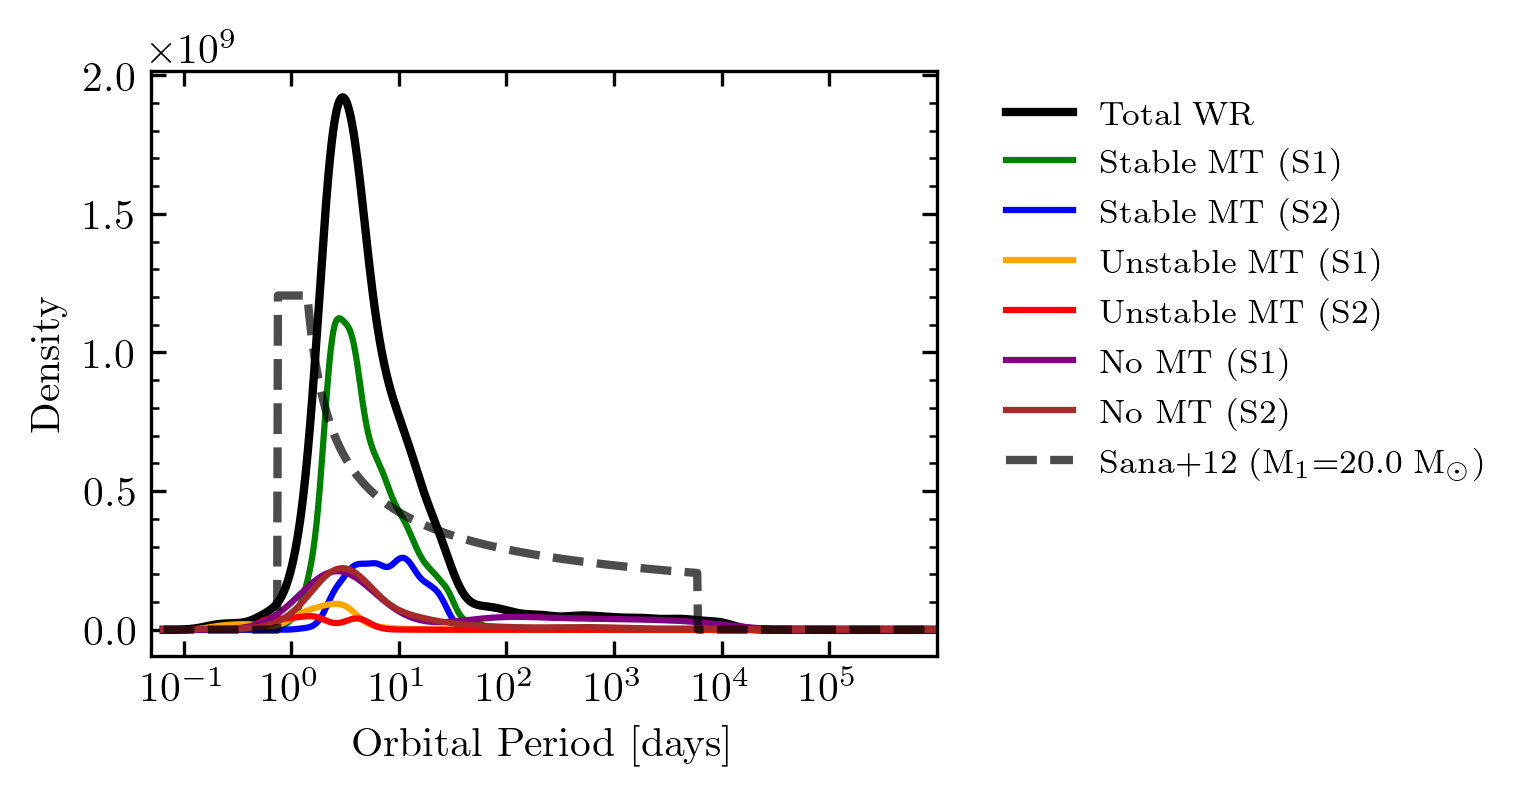

100%|██████████| 31411/31411 [00:25<00:00, 1245.57it/s]


Binary fraction among WR stars: 0.86
Missing ini parameter: metallicity


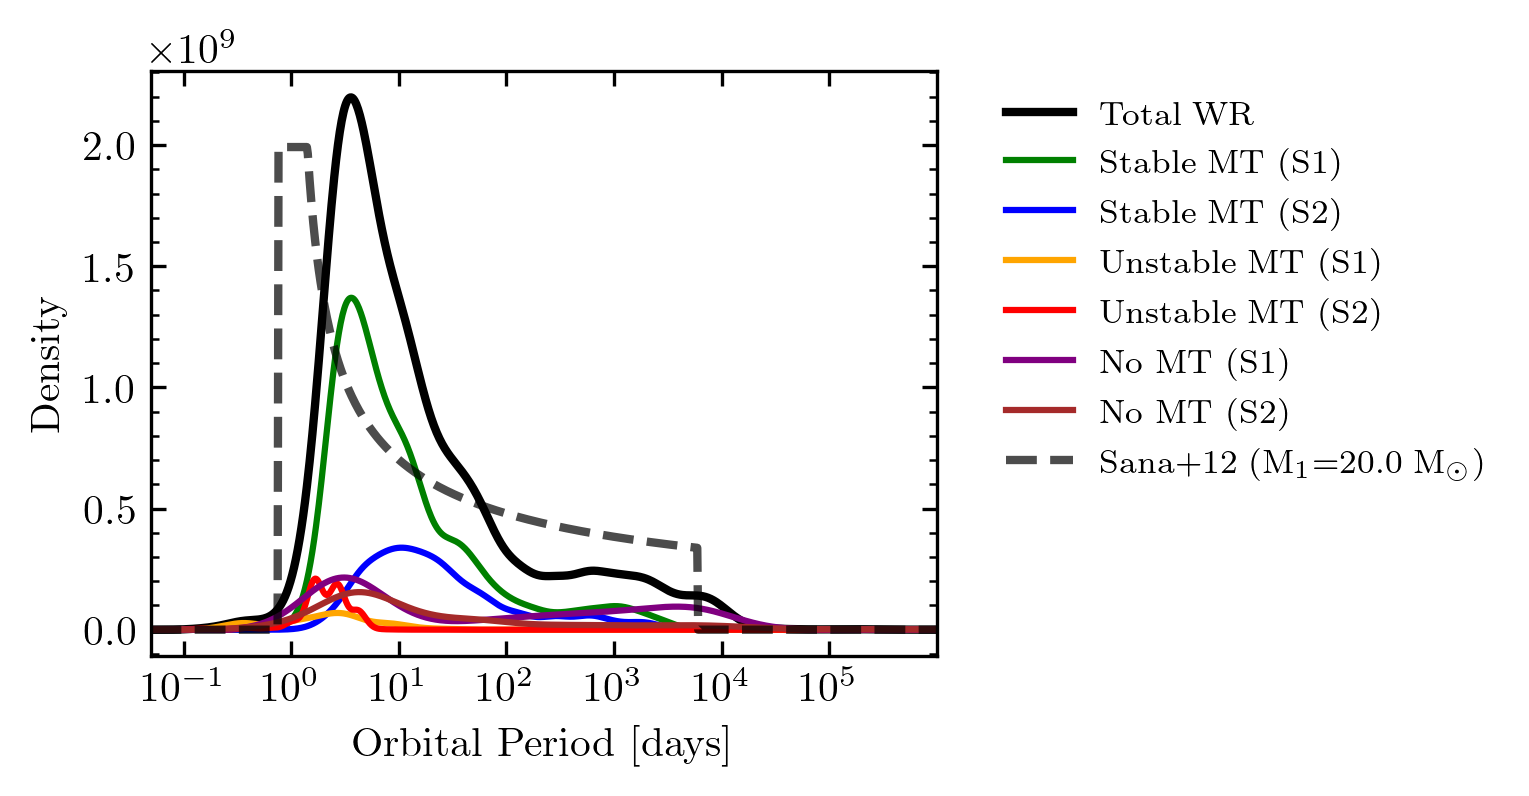

100%|██████████| 34399/34399 [00:29<00:00, 1170.66it/s]


Binary fraction among WR stars: 0.77
Missing ini parameter: metallicity


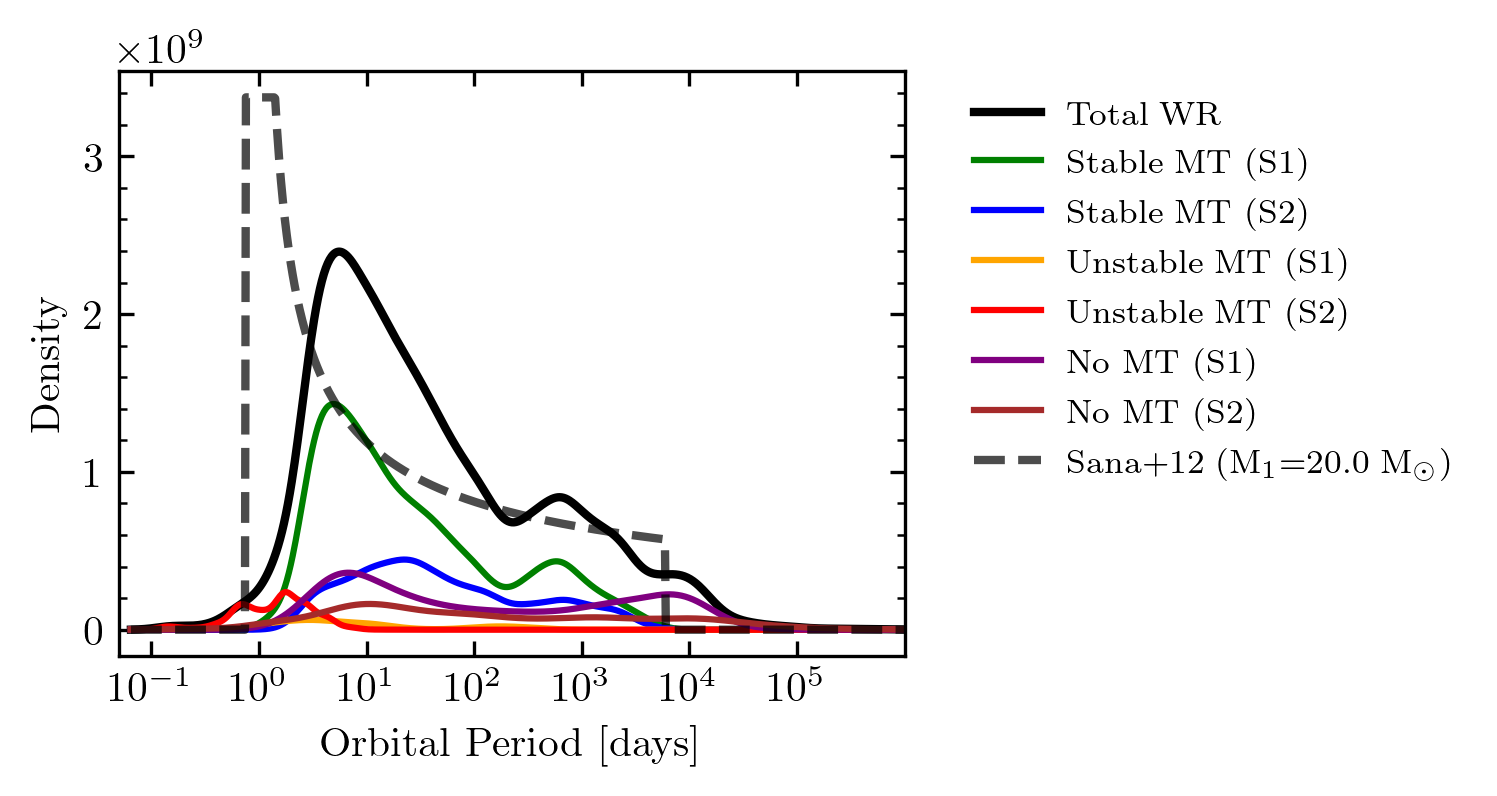

100%|██████████| 38190/38190 [00:25<00:00, 1518.49it/s]


Binary fraction among WR stars: 0.74
Missing ini parameter: metallicity


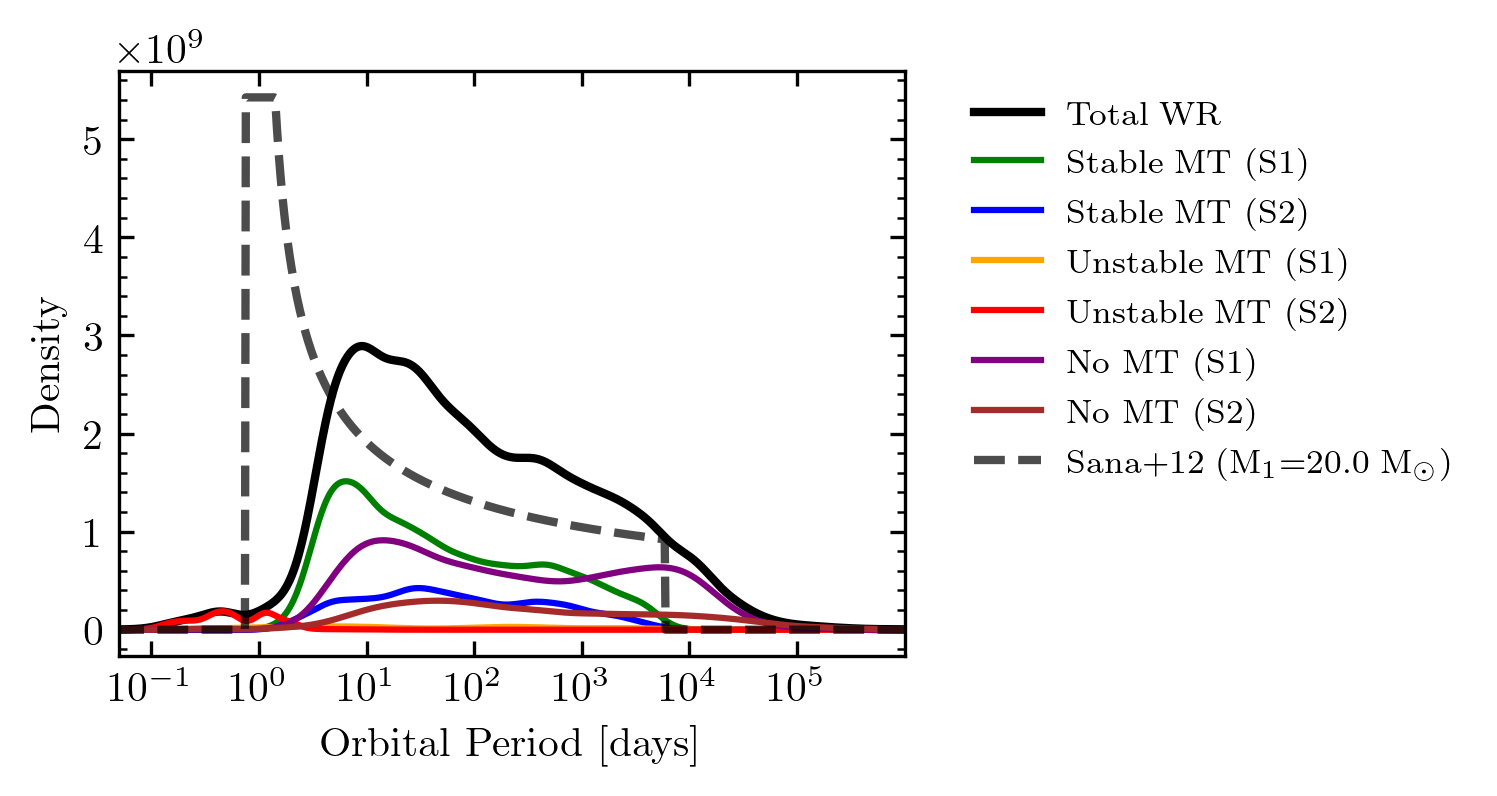

In [ ]:
from posydon.popsyn.synthetic_population import Population
import pandas as pd
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm

# Import Sana+12 period distribution
from posydon.popsyn.distributions import Sana12Period
from scipy.stats import gaussian_kde

from helper_functions import calc_Teff, classify_WR_type

fig, ax = plt.figure(2, 2, figsize=(3.38*2, 2.535*2))

# total WR, WC, WNE, WNL period distributions per metallicity.
# Each weighted relatively to solar metallicity total.

for metallicity in [0.2, 0.45, 1.0]:




    WNL =  (surface_H_array > 0.05) & (surface_H_array <= 0.4) & (optical_depth_array > 1.5) & ~(np.char.find(S1_state_array, 'H_burning') != -1)
    WNE = (surface_H_array <= 0.05) & (surface_He_array >= 0.7) & (optical_depth_array > 1.5)
    WC = (surface_H_array <= 0.001) & (surface_He_array < 0.7) & (optical_depth_array > 1.5)
    
    binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
    single_star_mask = (state_array == 'disrupted') | (state_array == 'merged')
    WR_binary_fraction = np.sum(weight_array[binary_mask & (WNL | WNE | WC)]) / np.sum(weight_array[(binary_mask | single_star_mask) & (WNL | WNE | WC)])
    print(f"Binary fraction among WR stars: {WR_binary_fraction:.2f}")

    WR_mask =( WNL | WNE | WC )

    # Define common x_eval range for ALL KDEs
    period_selection_all = period_array[(binary_mask) & (WR_mask)]
    x_eval = np.linspace(np.log10(np.min(period_selection_all)), np.log10(np.max(period_selection_all)), 1000)

    # Total WR distribution (for reference)
    period_selection = period_array[(binary_mask) & (WNL | WNE | WC)]
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL | WNE | WC)])
    kde_eval = kde(x_eval)
    ax[0].plot(10**x_eval, kde_eval*np.sum(weight_array[(binary_mask) & (WNL | WNE | WC)]), color='black', label='Total WR', linewidth=2)

    # Initialize sum
    h = np.zeros_like(x_eval)

    # Add Sana+12 initial period distribution
    # Create Sana+12 distribution object with the same period range as in the .ini file
    sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)

    # For massive stars (>15 Msun), evaluate the distribution
    # Use a representative mass of ~20 Msun for typical WR progenitor
    m_wr_progenitor = 20.0

    # Evaluate the PDF on the same x_eval grid (but in linear space)

    # normalised to 1 in logspace, so this should be fine.
    period_eval = 10**x_eval
    sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
    plt.plot(10**x_eval, sana_pdf*np.sum(weight_array[(binary_mask) & (WR_mask)]), 'k--', linewidth=2, alpha=0.7, 
            label=f'Sana+12 (M$_1$={m_wr_progenitor} M$_\odot$)')

    # Plot sum
    #plt.plot(10**x_eval, h, 'k--', label='Sum', linewidth=2)

    plt.xscale('log')
    plt.xlabel('Orbital Period [days]')
    plt.ylabel('Density')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    plt.xlim(0.05, 1e6)
    plt.xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
    plt.show()

100%|██████████| 38190/38190 [00:20<00:00, 1819.16it/s]


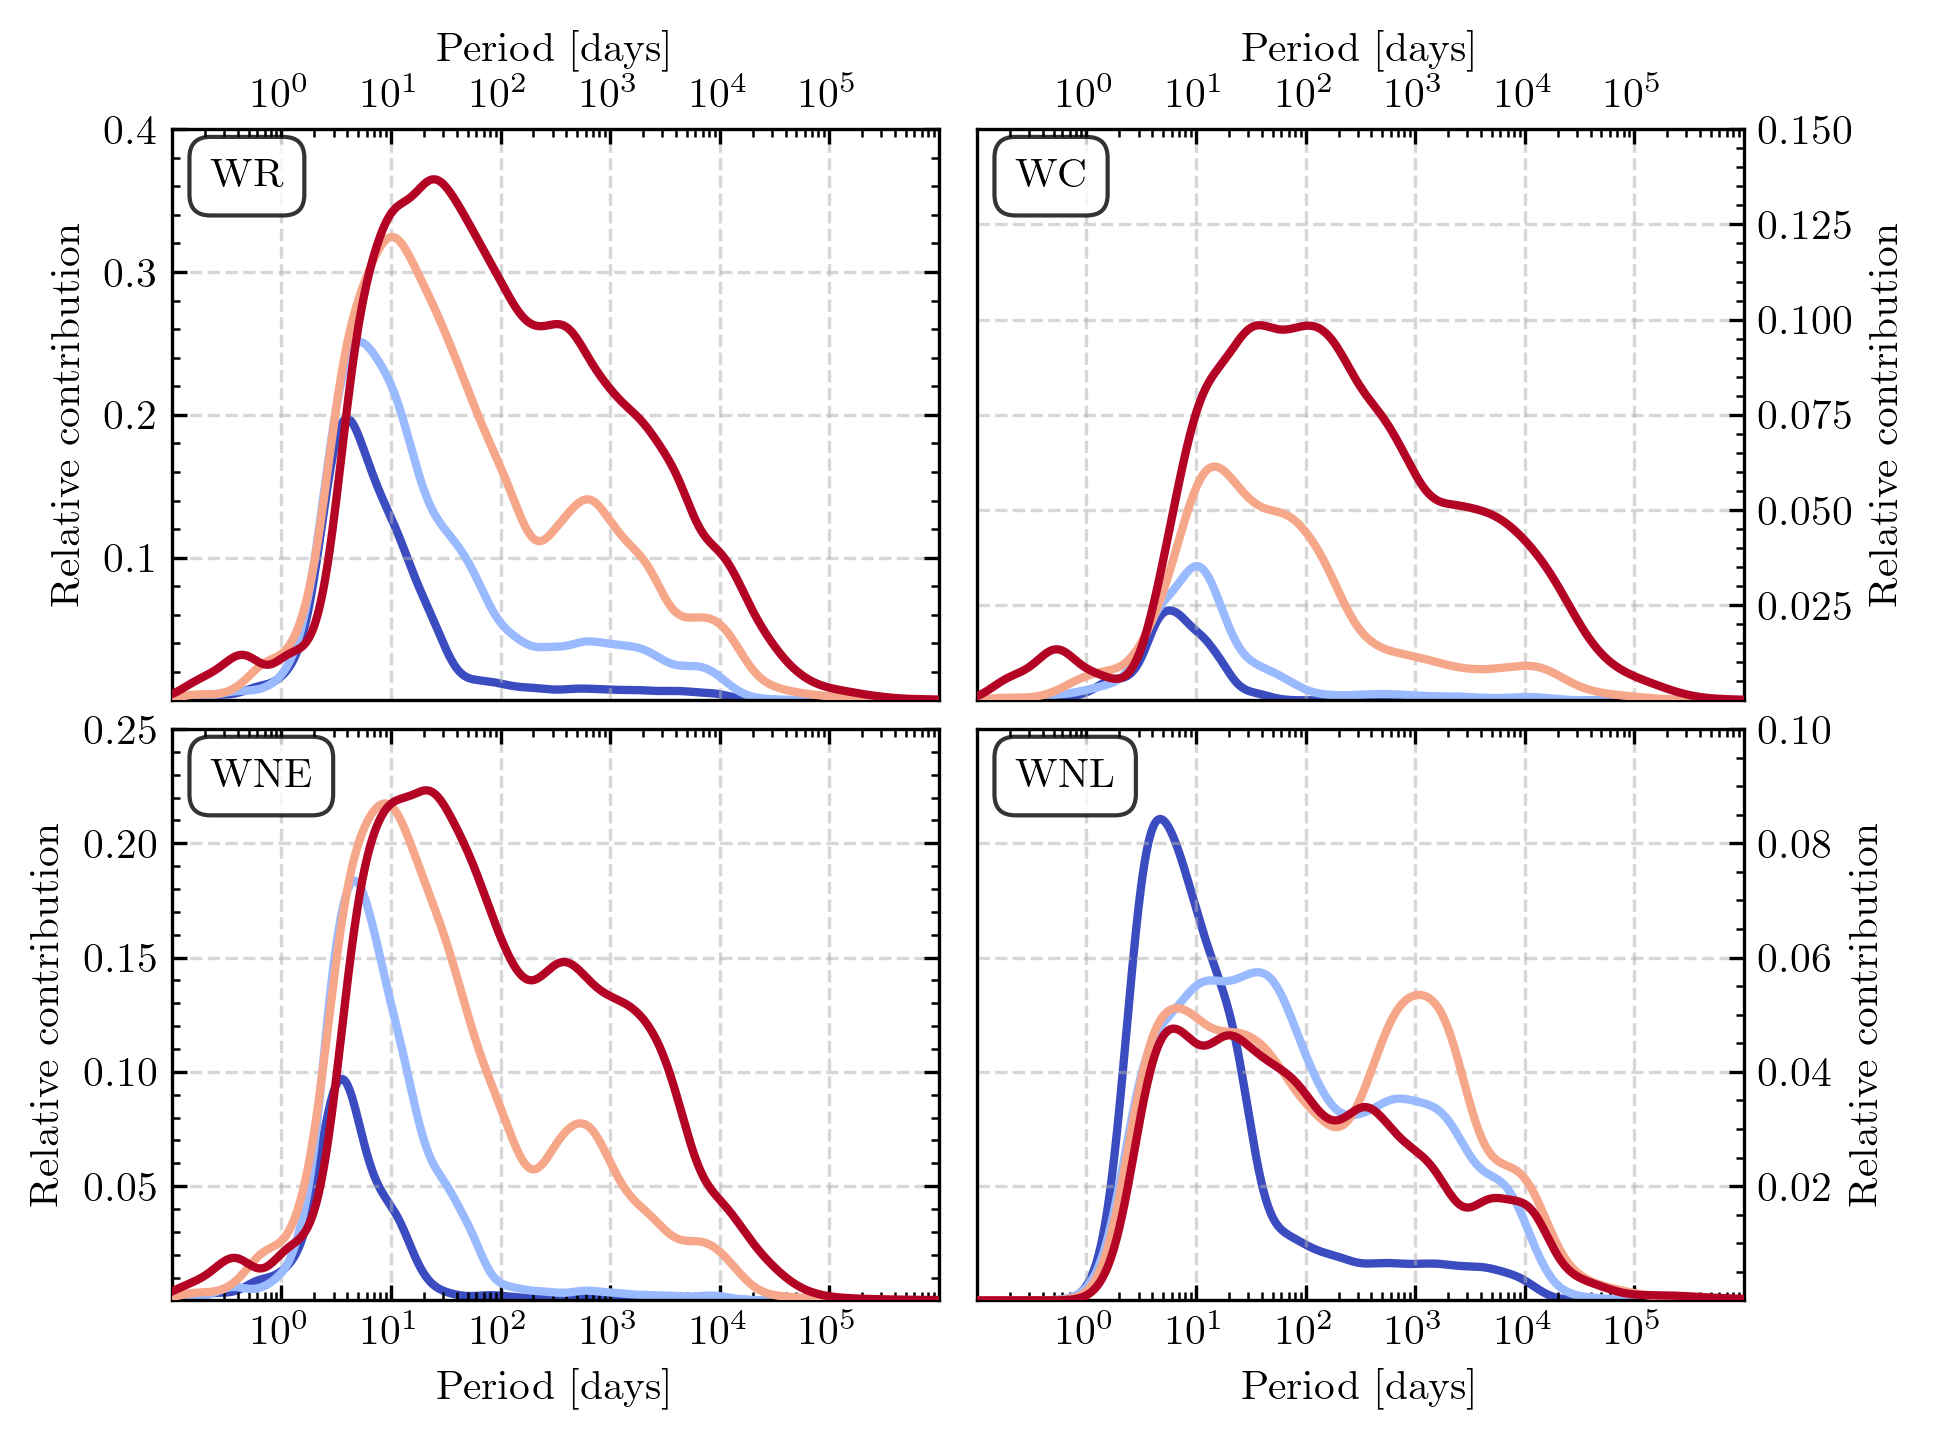

In [76]:
from posydon.popsyn.synthetic_population import Population
import pandas as pd
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm

# Import Sana+12 period distribution
from posydon.popsyn.distributions import Sana12Period
from scipy.stats import gaussian_kde

from helper_functions import calc_Teff, classify_WR_type

fig, axes = plt.subplots(2, 2, figsize=(3.38*2, 2.535*2))
plt.subplots_adjust(hspace=0.05, wspace=0.05)

color_per_met = [cmap_m(0), cmap_m(2), cmap_m(5), cmap_m(7)]

for metallicity, color in zip([0.1, 0.2, 0.45, 1.0], color_per_met):
    z_order = int(metallicity*10)  # Lower metallicity gets higher z-order

    data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
    met_str = convert_metallicity_to_string(metallicity)
    file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
        
    S1_WR_data = data['S1_WR_data']
    S2_WR_data = data['S2_WR_data']

    WR_types = []
    time_array = []
    weight_array = []
    state_array = []
    key_array = []
    star_array = []  # Track whether entry is from S1 or S2
    period_array = []
    separation_array = []
    Teff_array = []
    L_array = []
    optical_depth_array = []
    surface_H_array = []
    surface_He_array = []
    mass_array = []
    mass_companion_array = []
    radius_array = []
    Mdot_array = []
    companion_array = []
    S1_state_array = []
    surface_C = []
    optical_depth = []

    for key in tqdm(S1_WR_data):
        data = S1_WR_data[key]['data']
        weights = S1_WR_data[key]['weights']
        optical_depth_array.extend(S1_WR_data[key]['optical_depth'])
        
        surface_H_array.extend(data['S1_surface_h1'].values)
        surface_He_array.extend(data['S1_surface_he4'].values)
        Teff = 10**calc_Teff(data['S1_log_L'], data['S1_log_R'])
            
        time_array.extend(data['time'].values)
        weight_array.extend(weights)
        state_array.extend(data['state'].values)
        S1_state_array.extend(data['S1_state'].values)
        key_array.extend([key] * len(data))
        star_array.extend(['S1'] * len(data))  # Mark as S1
        Teff_array.extend(Teff)
        L_array.extend(10**data['S1_log_L'].values)
        mass_array.extend(data['S1_mass'].values)
        mass_companion_array.extend(data['S2_mass'].values)
        radius_array.extend(10**data['S1_log_R'].values)
        Mdot_array.extend(10**data['S1_lg_mdot'].values)
        companion_array.extend(data['S2_state'].values)
        
        period_array.extend(data['orbital_period'].values)
        sep = orbital_separation_from_period(data['orbital_period'].values,
                                            data['S1_mass'].values,
                                            data['S2_mass'].values)
        
        separation_array.extend(sep)
        
        
    for key in tqdm(S2_WR_data):
        data = S2_WR_data[key]['data']
        weights = S2_WR_data[key]['weights']
        optical_depth_array.extend(S2_WR_data[key]['optical_depth'])
        
        surface_H_array.extend(data['S2_surface_h1'].values)
        surface_He_array.extend(data['S2_surface_he4'].values)
        Teff = 10**calc_Teff(data['S2_log_L'], data['S2_log_R'])
        
        time_array.extend(data['time'].values)
        weight_array.extend(weights)
        state_array.extend(data['state'].values)
        key_array.extend([key] * len(data))
        star_array.extend(['S2'] * len(data))  # Mark as S2
        Teff_array.extend(Teff)
        L_array.extend(10**data['S2_log_L'].values)
        mass_array.extend(data['S2_mass'].values)
        mass_companion_array.extend(data['S1_mass'].values)
        radius_array.extend(10**data['S2_log_R'].values)
        Mdot_array.extend(10**data['S2_lg_mdot'].values)
        companion_array.extend(data['S1_state'])
        period_array.extend(data['orbital_period'].values)
        sep = orbital_separation_from_period(data['orbital_period'].values,
                                            data['S2_mass'].values,
                                            data['S1_mass'].values)
        S1_state_array.extend(data['S2_state'].values)
        separation_array.extend(sep)
        

    WR_types = np.array(WR_types)
    time_array = np.array(time_array)
    weight_array = np.array(weight_array)
    state_array = np.array(state_array)
    key_array = np.array(key_array)
    star_array = np.array(star_array)  # Convert to array
    period_array = np.array(period_array)
    separation_array = np.array(separation_array)
    Teff_array = np.array(Teff_array)
    L_array = np.array(L_array)
    optical_depth_array = np.array(optical_depth_array)
    surface_H_array = np.array(surface_H_array)
    surface_He_array = np.array(surface_He_array)
    mass_array = np.array(mass_array)
    radius_array = np.array(radius_array)
    Mdot_array = np.array(Mdot_array)
    companion_array = np.array(companion_array)
    mass_companion_array = np.array(mass_companion_array)

    WNL =  (surface_H_array > 0.05) & (surface_H_array <= 0.4) & (optical_depth_array > 1.5) & ~(np.char.find(S1_state_array, 'H_burning') != -1)
    WNE = (surface_H_array <= 0.05) & (surface_He_array >= 0.7) & (optical_depth_array > 1.5)
    WC = (surface_H_array <= 0.001) & (surface_He_array < 0.7) & (optical_depth_array > 1.5)
    WR_mask =( WNL | WNE | WC )
        
    binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
        
    # plot WR total
    period_selection = period_array[(binary_mask) & (WNL | WNE | WC)]
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL | WNE | WC)])
    kde_eval = kde(x_eval)
    weight = np.sum(weight_array[(binary_mask) & (WNL | WNE | WC)]) / total_solar
    axes[0,0].plot(10**x_eval, kde_eval*weight, color=color, label='', linewidth=2, zorder=z_order)
    
    # plot WC 
    period_selection = period_array[(binary_mask) & WC]
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & WC])
    kde_eval = kde(x_eval)

    weight = np.sum(weight_array[(binary_mask) & WC]) / total_solar
    axes[0,1].plot(10**x_eval, kde_eval * weight, color=color, label='', linewidth=2, zorder=z_order)

    # plot WNE
    period_selection = period_array[(binary_mask) & WNE]
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & WNE])
    kde_eval = kde(x_eval)
    weight = np.sum(weight_array[(binary_mask) & WNE]) / total_solar
    axes[1,0].plot(10**x_eval, kde_eval * weight, color=color, label='', linewidth=2, zorder=z_order)

    # Plot WNL
    period_selection = period_array[(binary_mask) & WNL]
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & WNL])
    kde_eval = kde(x_eval)

    weight = np.sum(weight_array[(binary_mask) & WNL]) / total_solar
    axes[1,1].plot(10**x_eval, kde_eval * weight, color=color, label='', linewidth=2, zorder=z_order)

for ax in axes.flatten():
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xlabel('Period [days]')
    ax.set_ylabel('Relative contribution')
    ax.set_xticks([1, 10, 100, 1000, 10000, 100000])

    ax.grid(True, which='major', ls='--', alpha=0.5)
    
for ax in axes[0]:
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    ax.set_xticks([1, 10, 100, 1000, 10000, 100000])
    
for ax in axes[:,1]:
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position('right')
    
 
axes[0,0].set_ylim(1e-5, 0.4)
axes[0,1].set_ylim(1e-5, 0.15)
axes[1,0].set_ylim(1e-5, 0.25)
axes[1,1].set_ylim(1e-5, 0.1)

axes[0,0].text(0.05, 0.95, 'WR', transform=axes[0,0].transAxes, verticalalignment='top', horizontalalignment='left', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black', alpha=0.8))


axes[0,1].text(0.05, 0.95, 'WC', transform=axes[0,1].transAxes, verticalalignment='top', horizontalalignment='left', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black', alpha=0.8))

axes[1,0].text(0.05, 0.95, 'WNE', transform=axes[1,0].transAxes, verticalalignment='top', horizontalalignment='left', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black', alpha=0.8))

axes[1,1].text(0.05, 0.95, 'WNL', transform=axes[1,1].transAxes, verticalalignment='top', horizontalalignment='left', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='black', alpha=0.8))


figure_path = '/Users/max/Documents/projects/WR_population/analysis/figures'
plt.savefig(f'{figure_path}/png/period_per_metallicity.png', bbox_inches='tight')
plt.savefig(f'{figure_path}/pdf/period_per_metallicity.pdf', bbox_inches='tight')

plt.show()